<a href="https://colab.research.google.com/github/jayjadhav33/Student-Performance-Analysis/blob/main/Student_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##1 Data Loading & Cleaning

In [1]:
# Import the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile, os

sns.set_style("whitegrid")

with zipfile.ZipFile('/content/archive.zip') as z:
    z.extractall('/content/data')

print(os.listdir('/content/data'))

['StudentsPerformance.csv']


In [2]:
# Load the CSV file
df = pd.read_csv('/content/data/StudentsPerformance.csv')

print("Shape (rows, columns):", df.shape)    # Number of students and columns
print("\n--- First 5 rows ---")
display(df.head())                           # Preview the data

print("\n--- Data types ---")
print(df.dtypes)                             # Check each column's type

print("\n--- Missing values per column ---")
print(df.isnull().sum())                     # Count nulls in each column

print("\n--- Duplicate rows ---")
print(df.duplicated().sum())                 # Count fully duplicated rows

print("\n--- Summary statistics ---")
display(df.describe())                       # Min, max, mean of score columns

print("\n--- Unique values in categorical columns ---")
for col in df.select_dtypes(include='object').columns:
    print(f"{col}: {df[col].unique().tolist()}")

Shape (rows, columns): (1000, 8)

--- First 5 rows ---


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75



--- Data types ---
gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object

--- Missing values per column ---
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

--- Duplicate rows ---
0

--- Summary statistics ---


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



--- Unique values in categorical columns ---
gender: ['female', 'male']
race/ethnicity: ['group B', 'group C', 'group A', 'group D', 'group E']
parental level of education: ["bachelor's degree", 'some college', "master's degree", "associate's degree", 'high school', 'some high school']
lunch: ['standard', 'free/reduced']
test preparation course: ['none', 'completed']


In [3]:
# Rename columns to short, easy names
df.columns = ['gender', 'race', 'parent_edu', 'lunch', 'test_prep',
              'math', 'reading', 'writing']

# Create total score (out of 300) and average score (out of 100)
df['total'] = df['math'] + df['reading'] + df['writing']
df['average'] = (df['total'] / 3).round(2)

# Sanity check: all scores should be between 0 and 100
print(df[['math', 'reading', 'writing']].agg(['min', 'max']))

df.head()

     math  reading  writing
min     0       17       10
max   100      100      100


,gender,race,parent_edu,lunch,test_prep,math,reading,writing,total,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.67
1,female,group C,some college,standard,completed,69,90,88,247,82.33
2,female,group B,master's degree,standard,none,90,95,93,278,92.67
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.33
4,male,group C,some college,standard,none,76,78,75,229,76.33


Column Meanings:

gender: male or female

race: anonymised ethnic group (group A to E)

parent_edu: highest education level of the student’s parents

lunch: standard or free/reduced (a rough indicator of family income)

test_prep: whether the student completed the test preparation course

math, reading, writing: exam scores out of 100

total, average: columns we created

## 2. Factor Analysis

In [4]:
# Average total score for each parental education level, highest first
edu_avg = df.groupby('parent_edu')['total'].mean().sort_values(ascending=False)

print("Q1: Does parental education level affect scores?")
print("-" * 65)
print(f"Education level with highest average score : {edu_avg.index[0]} "
      f"with average total score {edu_avg.iloc[0]:.2f} / 300")
print(f"Education level with lowest average score  : {edu_avg.index[-1]} "
      f"with average total score {edu_avg.iloc[-1]:.2f} / 300")
print(f"Gap between highest and lowest             : {edu_avg.iloc[0] - edu_avg.iloc[-1]:.2f} points")

print("\nRemaining education levels and their average total score (descending order):")
for level, score in edu_avg.iloc[1:].items():
    print(f"  {level:<22} {score:>7.2f}")

print("\nSubject-wise averages by parental education:")
display(df.groupby('parent_edu')[['math', 'reading', 'writing']].mean().round(2).loc[edu_avg.index])

Q1: Does parental education level affect scores?
-----------------------------------------------------------------
Education level with highest average score : master's degree with average total score 220.80 / 300
Education level with lowest average score  : high school with average total score 189.29 / 300
Gap between highest and lowest             : 31.51 points

Remaining education levels and their average total score (descending order):
  bachelor's degree       215.77
  associate's degree      208.71
  some college            205.43
  some high school        195.32
  high school             189.29

Subject-wise averages by parental education:


,math,reading,writing
parent_edu,,,
master's degree,69.75,75.37,75.68
bachelor's degree,69.39,73.00,73.38
associate's degree,67.88,70.93,69.90
some college,67.13,69.46,68.84
some high school,63.50,66.94,64.89
high school,62.14,64.70,62.45


In [5]:
# Average scores for students who completed vs did not complete test prep
prep_avg = df.groupby('test_prep')['total'].mean().sort_values(ascending=False)
prep_count = df['test_prep'].value_counts()

print("Q2: Do students who complete test prep score higher?")
print("-" * 65)
print(f"Group with higher average score : {prep_avg.index[0]} "
      f"with average total score {prep_avg.iloc[0]:.2f} / 300")

print("\nRemaining group and its average total score:")
print(f"  {prep_avg.index[1]:<12} {prep_avg.iloc[1]:>7.2f}")

diff = prep_avg.iloc[0] - prep_avg.iloc[1]
print(f"\nDifference : {diff:.2f} points ({diff / prep_avg.iloc[1] * 100:.1f}% higher)")
print(f"Number of students : completed = {prep_count['completed']}, none = {prep_count['none']}")

print("\nSubject-wise averages by test prep:")
display(df.groupby('test_prep')[['math', 'reading', 'writing']].mean().round(2))

Q2: Do students who complete test prep score higher?
-----------------------------------------------------------------
Group with higher average score : completed with average total score 218.01 / 300

Remaining group and its average total score:
  none          195.12

Difference : 22.89 points (11.7% higher)
Number of students : completed = 358, none = 642

Subject-wise averages by test prep:


,math,reading,writing
test_prep,,,
completed,69.70,73.89,74.42
none,64.08,66.53,64.50


In [6]:
from itertools import combinations

corr = df[['math', 'reading', 'writing']].corr()   # Correlation matrix

# Collect every pair of subjects with its correlation value
pairs = [(a, b, corr.loc[a, b]) for a, b in combinations(corr.columns, 2)]
pairs = sorted(pairs, key=lambda x: x[2], reverse=True)   # Strongest first

print("Q3: What is the correlation between reading, writing, and math scores?")
print("-" * 65)
print(f"Strongest correlation : {pairs[0][0]} and {pairs[0][1]} with correlation {pairs[0][2]:.3f}")

print("\nRemaining subject pairs and their correlation (descending order):")
for a, b, val in pairs[1:]:
    print(f"  {a} and {b:<10} {val:.3f}")

print("\nFull correlation matrix:")
display(corr.round(3))

Q3: What is the correlation between reading, writing, and math scores?
-----------------------------------------------------------------
Strongest correlation : reading and writing with correlation 0.955

Remaining subject pairs and their correlation (descending order):
  math and reading    0.818
  math and writing    0.803

Full correlation matrix:


,math,reading,writing
math,1.000,0.818,0.803
reading,0.818,1.000,0.955
writing,0.803,0.955,1.000


In [7]:
# Average score per subject for each gender
gender_avg = df.groupby('gender')[['math', 'reading', 'writing']].mean()

print("Q4: Which gender performs better in which subject?")
print("-" * 65)

female_leads, male_leads = [], []
for subject in ['math', 'reading', 'writing']:
    f, m = gender_avg.loc['female', subject], gender_avg.loc['male', subject]
    winner = 'female' if f > m else 'male'
    (female_leads if winner == 'female' else male_leads).append(subject)
    print(f"{subject.capitalize():<8}: female {f:.2f} vs male {m:.2f}  ->  "
          f"{winner} leads by {abs(f - m):.2f} points")

print(f"\nFemale students perform better in : {', '.join(female_leads) if female_leads else 'none'}")
print(f"Male students perform better in   : {', '.join(male_leads) if male_leads else 'none'}")

Q4: Which gender performs better in which subject?
-----------------------------------------------------------------
Math    : female 63.63 vs male 68.73  ->  male leads by 5.10 points
Reading : female 72.61 vs male 65.47  ->  female leads by 7.14 points
Writing : female 72.47 vs male 63.31  ->  female leads by 9.16 points

Female students perform better in : reading, writing
Male students perform better in   : math


In [8]:
# Summary statistics of total score
t = df['total']

print("Q5: What is the distribution of total scores?")
print("-" * 65)
print(f"Average total score : {t.mean():.2f} / 300")
print(f"Median total score  : {t.median():.2f}")
print(f"Std deviation       : {t.std():.2f}")
print(f"Lowest / Highest    : {t.min()} / {t.max()}")
print(f"25th / 75th percentile : {t.quantile(0.25):.0f} / {t.quantile(0.75):.0f}")

# Group scores into ranges of width 30
bins = np.arange(0, 301, 30)
labels = [f"{b}-{b+30}" for b in bins[:-1]]
ranges = pd.cut(t, bins=bins, labels=labels, include_lowest=True)
range_counts = ranges.value_counts().sort_values(ascending=False)
range_counts = range_counts[range_counts > 0]          # Hide empty ranges

print(f"\nMost common score range : {range_counts.index[0]} with {range_counts.iloc[0]} students "
      f"({range_counts.iloc[0] / len(df) * 100:.1f}%)")

print("\nRemaining score ranges and number of students (descending order):")
for rng, cnt in range_counts.iloc[1:].items():
    print(f"  {rng:<10} {cnt:>4} students   ({cnt / len(df) * 100:.1f}%)")

Q5: What is the distribution of total scores?
-----------------------------------------------------------------
Average total score : 203.31 / 300
Median total score  : 205.00
Std deviation       : 42.77
Lowest / Highest    : 27 / 300
25th / 75th percentile : 175 / 233

Most common score range : 180-210 with 260 students (26.0%)

Remaining score ranges and number of students (descending order):
  210-240     253 students   (25.3%)
  150-180     184 students   (18.4%)
  240-270     144 students   (14.4%)
  120-150      77 students   (7.7%)
  270-300      50 students   (5.0%)
  90-120       22 students   (2.2%)
  60-90         8 students   (0.8%)
  30-60         1 students   (0.1%)
  0-30          1 students   (0.1%)


## 3. Visualisations

/tmp/ipykernel_3607/1864793380.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='parent_edu', y='total',               # One box per education level


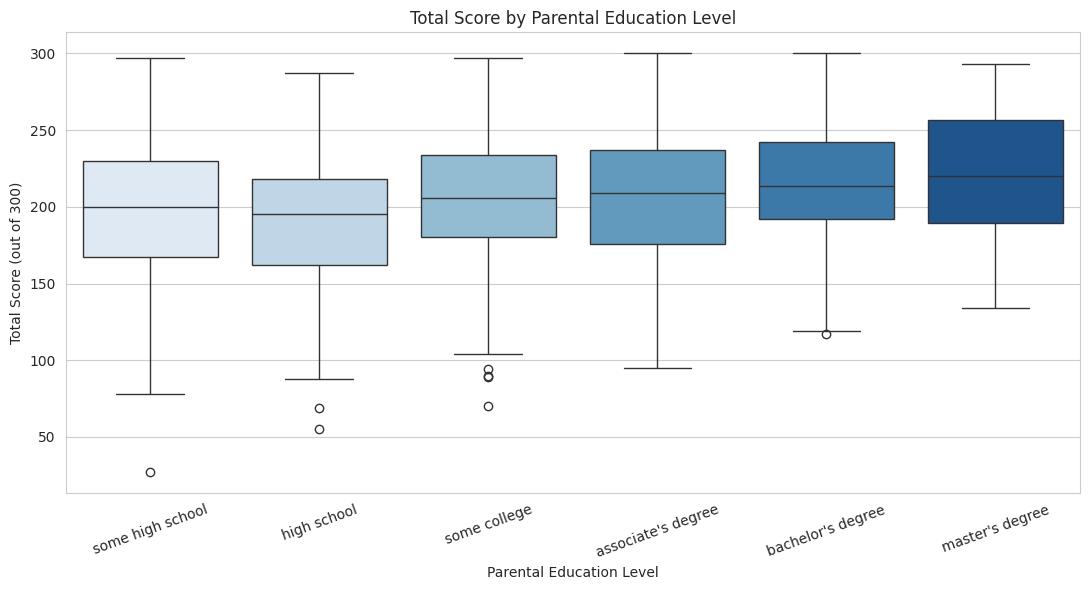

In [9]:
# CHART 1: Box plot - Total score by parental education level

# Fixed order from lowest to highest education so the chart reads logically
edu_order = ['some high school', 'high school', 'some college',
             "associate's degree", "bachelor's degree", "master's degree"]

plt.figure(figsize=(11, 6))                                   # Chart size
sns.boxplot(data=df, x='parent_edu', y='total',               # One box per education level
            order=edu_order, palette='Blues')                 # Apply the order above
plt.title('Total Score by Parental Education Level')          # Title
plt.xlabel('Parental Education Level')                        # x-axis label
plt.ylabel('Total Score (out of 300)')                        # y-axis label
plt.xticks(rotation=20)                                       # Tilt labels so they don't overlap
plt.tight_layout()                                            # Prevent cut-off labels
plt.show()

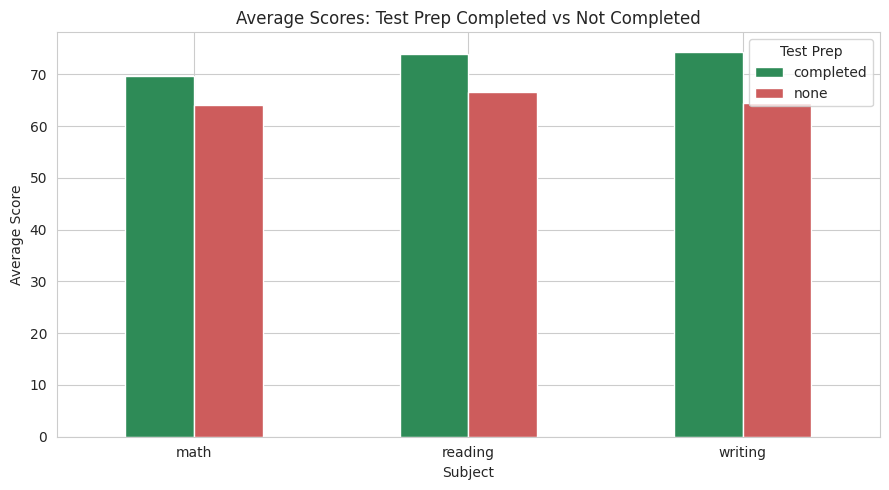

In [10]:
# CHART 2: Bar chart - Average scores with vs without test prep

prep_scores = df.groupby('test_prep')[['math', 'reading', 'writing']].mean()   # Average per subject

prep_scores.T.plot(kind='bar', figsize=(9, 5),                # .T puts subjects on the x-axis
                   color=['seagreen', 'indianred'])           # One colour per group
plt.title('Average Scores: Test Prep Completed vs Not Completed')
plt.xlabel('Subject')
plt.ylabel('Average Score')
plt.xticks(rotation=0)                                        # Keep subject names horizontal
plt.legend(title='Test Prep')                                 # Legend explains the colours
plt.tight_layout()
plt.show()

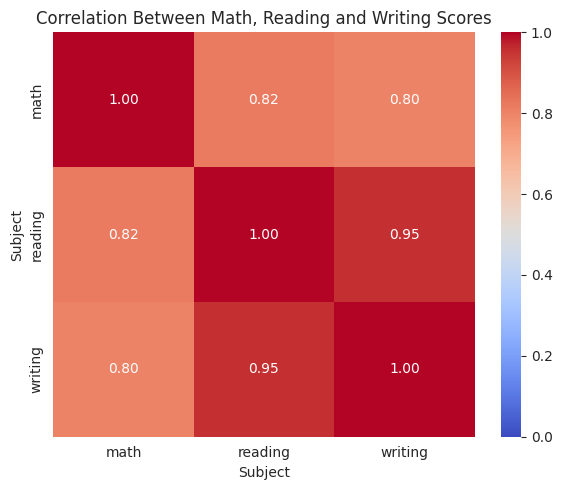

In [11]:
# CHART 3: Heatmap - Correlation between the three subjects

plt.figure(figsize=(6, 5))
sns.heatmap(df[['math', 'reading', 'writing']].corr(),        # Correlation matrix
            annot=True,                                       # Print the value in each cell
            cmap='coolwarm', vmin=0, vmax=1, fmt='.2f')       # Colour scale from 0 to 1
plt.title('Correlation Between Math, Reading and Writing Scores')
plt.xlabel('Subject')
plt.ylabel('Subject')
plt.tight_layout()
plt.show()

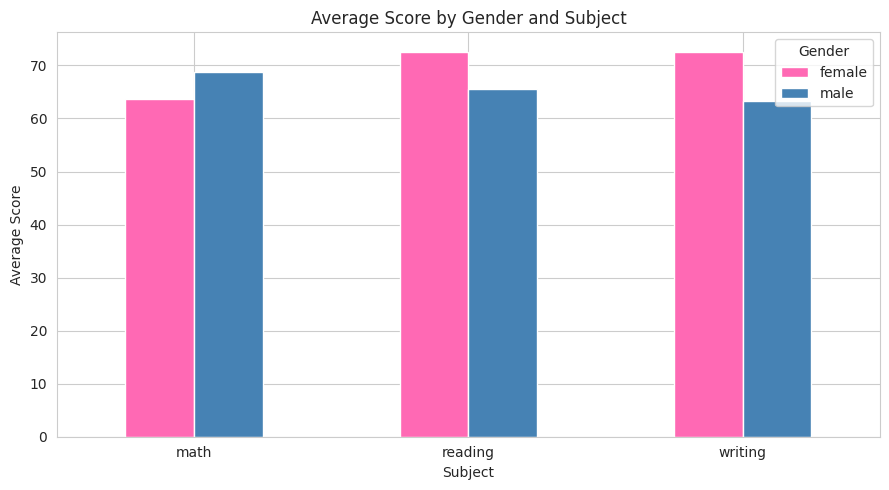

In [12]:
# CHART 4: Grouped bar chart - Average score by gender for each subject

gender_scores = df.groupby('gender')[['math', 'reading', 'writing']].mean()

gender_scores.T.plot(kind='bar', figsize=(9, 5),              # Subjects on x-axis, one bar per gender
                     color=['hotpink', 'steelblue'])
plt.title('Average Score by Gender and Subject')
plt.xlabel('Subject')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend(title='Gender')
plt.tight_layout()
plt.show()

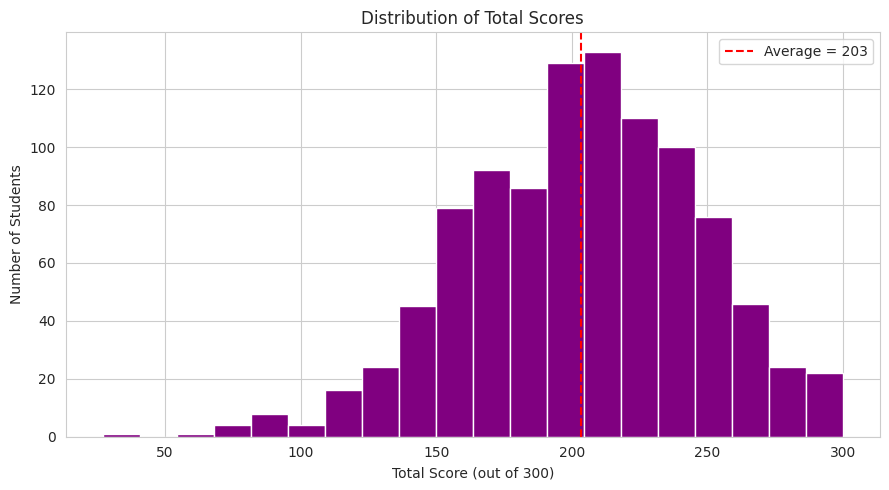

In [13]:
# CHART 5: Histogram - How total scores are distributed

plt.figure(figsize=(9, 5))
plt.hist(df['total'], bins=20, color='purple', edgecolor='white')    # 20 bars, white edges for clarity
plt.axvline(df['total'].mean(), color='red', linestyle='--',         # Dashed line marking the average
            label=f"Average = {df['total'].mean():.0f}")
plt.title('Distribution of Total Scores')
plt.xlabel('Total Score (out of 300)')
plt.ylabel('Number of Students')                                     # Bar height = students in that range
plt.legend()
plt.tight_layout()
plt.show()

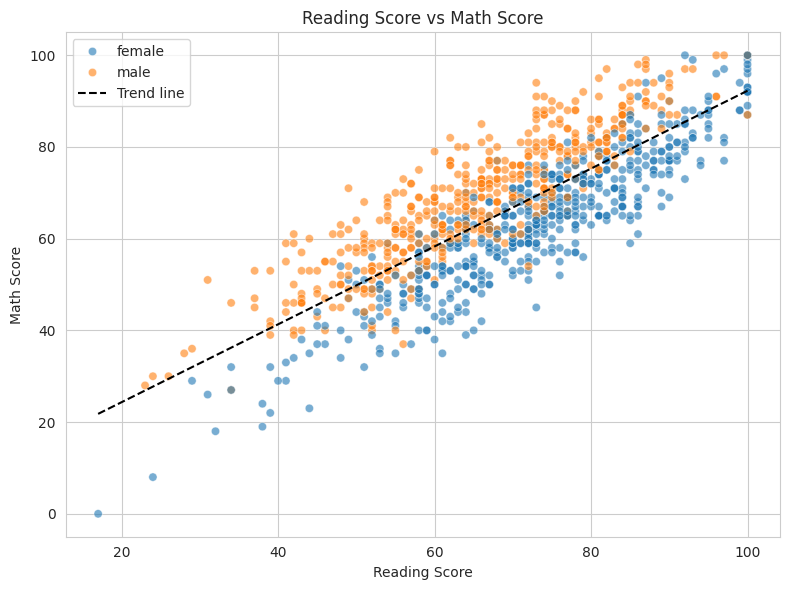

In [14]:
# CHART 6: Scatter plot - Relationship between reading and math scores

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='reading', y='math',               # Each dot is one student
                hue='gender', alpha=0.6)                      # Colour by gender, slightly transparent

# Add a straight trend line (best fit) through all the points
slope, intercept = np.polyfit(df['reading'], df['math'], 1)   # Fit y = slope*x + intercept
x_vals = np.array([df['reading'].min(), df['reading'].max()])
plt.plot(x_vals, slope * x_vals + intercept, color='black', linestyle='--', label='Trend line')

plt.title('Reading Score vs Math Score')
plt.xlabel('Reading Score')
plt.ylabel('Math Score')
plt.legend()
plt.tight_layout()
plt.show()

## 4. At-Risk Student Segmentation

In [15]:
# A student is at-risk if ANY subject score is below 50
df['at_risk'] = ((df['math'] < 50) | (df['reading'] < 50) | (df['writing'] < 50))

total_students = len(df)
risk_count = df['at_risk'].sum()

print("At-Risk Student Count")
print("-" * 65)
print(f"Total students       : {total_students}")
print(f"At-risk students     : {risk_count} ({risk_count / total_students * 100:.1f}%)")
print(f"Not at-risk students : {total_students - risk_count} ({(total_students - risk_count) / total_students * 100:.1f}%)")

print("\nAt-risk students by subject (scoring below 50):")
for s in ['math', 'reading', 'writing']:
    print(f"  {s.capitalize():<8} {(df[s] < 50).sum()} students")

At-Risk Student Count
-----------------------------------------------------------------
Total students       : 1000
At-risk students     : 188 (18.8%)
Not at-risk students : 812 (81.2%)

At-risk students by subject (scoring below 50):
  Math     135 students
  Reading  90 students
  Writing  114 students


In [16]:
# Calculate at-risk percentage for every group in every category
rows = []
for col in ['gender', 'parent_edu', 'test_prep', 'lunch', 'race']:
    for group, sub in df.groupby(col):
        rows.append({'Category': col,
                     'Group': group,
                     'Students': len(sub),
                     'At-Risk': int(sub['at_risk'].sum()),
                     'At-Risk %': round(sub['at_risk'].mean() * 100, 1)})

seg = pd.DataFrame(rows).sort_values('At-Risk %', ascending=False).reset_index(drop=True)

print("Highest at-risk group overall : "
      f"{seg.loc[0, 'Category']} = {seg.loc[0, 'Group']} with {seg.loc[0, 'At-Risk %']}% at-risk "
      f"({seg.loc[0, 'At-Risk']} of {seg.loc[0, 'Students']} students)")

print("\nFull segmentation table (descending order of at-risk %):")
display(seg)

print("\nHighest at-risk group within each category:")
for col in seg['Category'].unique():
    top = seg[seg['Category'] == col].iloc[0]
    print(f"  {col:<12} {top['Group']:<22} {top['At-Risk %']}%")

Highest at-risk group overall : race = group A with 33.7% at-risk (30 of 89 students)

Full segmentation table (descending order of at-risk %):


,Category,Group,Students,At-Risk,At-Risk %
0,race,group A,89,30,33.7
1,lunch,free/reduced,355,111,31.3
2,parent_edu,some high school,179,46,25.7
3,parent_edu,high school,196,49,25.0
4,test_prep,none,642,152,23.7
5,race,group B,190,43,22.6
6,gender,male,482,99,20.5
7,race,group C,319,59,18.5
8,gender,female,518,89,17.2
9,parent_edu,some college,226,38,16.8



Highest at-risk group within each category:
  race         group A                33.7%
  lunch        free/reduced           31.3%
  parent_edu   some high school       25.7%
  test_prep    none                   23.7%
  gender       male                   20.5%


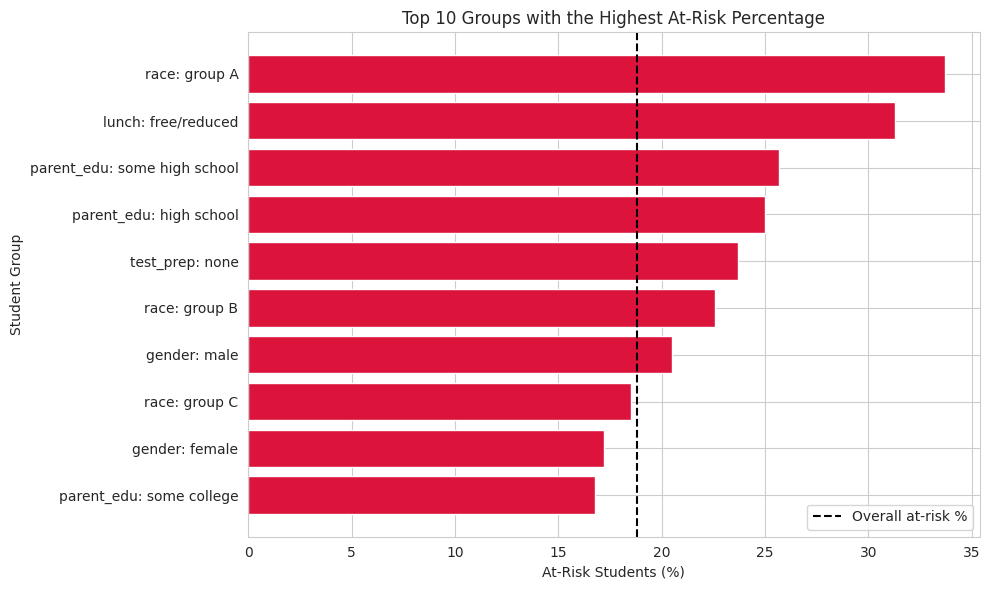

In [17]:
# BONUS CHART: At-risk percentage for the top 10 groups

top_groups = seg.head(10).copy()
top_groups['Label'] = top_groups['Category'] + ': ' + top_groups['Group']   # e.g. "lunch: free/reduced"

plt.figure(figsize=(10, 6))
plt.barh(top_groups['Label'][::-1], top_groups['At-Risk %'][::-1], color='crimson')   # [::-1] puts highest on top
plt.axvline(risk_count / total_students * 100, color='black', linestyle='--',          # Overall average line
            label='Overall at-risk %')
plt.title('Top 10 Groups with the Highest At-Risk Percentage')
plt.xlabel('At-Risk Students (%)')
plt.ylabel('Student Group')
plt.legend()
plt.tight_layout()
plt.show()

### 7.4 Analysis of At-Risk Students

**Definition:** A student is classified as at-risk if they score below 50 in any one subject (math, reading, or writing).

**Overall picture**
- 188 of 1,000 students (18.8%) are at-risk.
- Math is the weakest subject: 135 students scored below 50, compared with 114 in writing and 90 in reading.
- The subject counts add up to more than 188 because some students scored below 50 in more than one subject.

**Groups with the highest at-risk percentage**

| Rank | Group | At-Risk % | Compared with overall (18.8%) |
|---|---|---|---|
| 1 | Race: Group A | 33.7% (30 of 89) | about 1.8x higher |
| 2 | Lunch: free/reduced | 31.3% (111 of 355) | about 1.7x higher |
| 3 | Parental education: some high school | 25.7% (46 of 179) | about 1.4x higher |
| 4 | Parental education: high school | 25.0% (49 of 196) | about 1.3x higher |
| 5 | Test prep: none | 23.7% (152 of 642) | about 1.3x higher |

**Key observations**
1. **Family income (lunch type):** Students on free/reduced lunch are at-risk at 31.3%, compared with 11.9% for standard lunch, which is about 2.6 times higher. These students make up 111 of the 188 at-risk students (about 59%).
2. **Test preparation:** 23.7% of students who did not complete test prep are at-risk, compared with 10.1% of those who did, about 2.3 times higher. Students with no test prep account for 152 of the 188 at-risk students (about 81%).
3. **Parental education:** The at-risk rate falls steadily as parental education rises, from 25.7% (some high school) to 10.2% (master's degree). Students whose parents did not go beyond high school are at higher risk than the school average.
4. **Gender:** Male students (20.5%) are slightly more at-risk than female students (17.2%), a gap of 3.3 percentage points. This is a smaller difference than the other factors.
5. **Race/ethnic group:** Group A has the highest at-risk rate (33.7%), while Group E has the lowest (10.0%). Group A has only 89 students, so this figure should be read with some caution.

**Possible reasons**
- Free/reduced lunch is an indicator of lower family income, which may limit access to study materials, tutoring, and a quiet place to study.
- Students who skipped test prep may have had less structured practice and less exam familiarity.
- Parents with lower education levels may be less able to help with schoolwork or may have less awareness of academic support options.

**Conclusion:** Students on free/reduced lunch, students who did not complete test prep, and students whose parents have a high school education or less are the main groups the school should prioritise. Together with extra support in math, these groups offer the best chance to reduce the at-risk percentage.

## 5. Principal's Report

### Executive Summary

I analyzed the exam results of 1,000 students to understand what influences their performance and to identify students who may need extra academic support. Test preparation, lunch type (used as an indicator of family income), and parental education were the factors most strongly linked to student scores, and 188 students (18.8%) scored below 50 in at least one subject. To improve next year's results, the school should make test preparation more accessible and provide additional support to the students most at risk of falling behind.

### Key Findings

**1. Parental education is linked to student performance.**

Students whose parents held a master's degree scored an average of 220.80 out of 300, compared with 189.29 for students whose parents had completed high school. That's a difference of around 31.5 points (Chart 1, Q1). Interestingly, students whose parents had attended some high school but hadn't graduated scored 195.32, slightly higher than those whose parents had completed high school. This suggests that the relationship between parental education and student performance isn't always straightforward.

**2. Test preparation is associated with higher scores.**

Students who completed the test prep course had an average score of 218.01, compared with 195.12 for those who didn't. That's a difference of 22.9 points, or around 11.7%. The same trend appeared across all three subjects (Chart 2, Q2). However, this doesn't necessarily mean the course alone caused the improvement. Factors such as student motivation and study habits may also have played a role.

**3. Performance across subjects is closely connected.**

Reading and writing scores have a very strong correlation of 0.955. Math scores are also strongly correlated with reading (0.82) and writing (0.80) (Chart 3, Q3). This means students who struggle in one subject may also face difficulties in others. As a result, academic support should focus on a student's overall progress rather than treating each subject as a separate problem.

**4. There are noticeable gender differences in subject scores.**

Girls scored higher than boys in reading (72.6 compared with 65.5) and writing (72.5 compared with 63.3). Boys, on the other hand, performed better in math, with an average score of 68.7 compared with 63.6 for girls. The largest gap was in writing, where girls scored 9.2 points higher than boys (Chart 4, Q4).

**5. Most students are performing reasonably well, but some need additional support.**

The average total score was 203.3, with roughly half of the scores falling between 180 and 240 (Chart 5, Q5). Still, 188 students (18.8%) scored below 50 in at least one subject. Math had the highest number of students scoring below 50, with 135 students affected.

The risk of underperformance was considerably higher among students receiving free or reduced-price lunch, at 31.3%, compared with 11.9% among standard-lunch students. Similarly, 23.7% of students who didn't complete test prep were at risk, compared with 10.1% of those who did.

### Recommendations

**1. Make test preparation accessible to students who need it most.**

The school should expand access to test prep, starting with students receiving free or reduced-price lunch. Students who didn't complete test prep accounted for 152 of the 188 at-risk students, making them an important group to focus on. The school could offer the course free of charge, with reserved seats for students who face financial or academic barriers. Making the program available to everyone who needs it could help improve overall performance while supporting those who need it most.

**2. Introduce subject-specific academic support, with a focus on math.**

Since math had the highest number of students scoring below 50, the school should consider starting weekly small-group math sessions. These sessions could help students strengthen basic concepts and get individual attention. Additional reading and writing workshops could also be introduced to address the performance gaps between boys and girls. A supportive math confidence group for girls may also be worth exploring, while ensuring that all students have access to the resources they need.

**3. Set up an early-warning system and after-school homework club.**

Teachers could identify students who score below 50 in their first-term exams and refer them for mentoring or extra academic support. This would help the school step in before students fall further behind. Students whose parents have a high school education or less also showed relatively high risk levels, ranging from 25.0% to 25.7%. An after-school homework club could give these students a place to complete assignments, ask questions, and receive guidance they may not always have access to at home.

### Note on the Most Impactful Recommendation

I believe the most impactful recommendation would be to make test preparation accessible to all students who need it. This is a practical step the school can take directly, and the difference in average scores between students who completed the course and those who didn't was significant, at 22.9 points. It also connects with the other findings, since students who didn't complete test prep made up most of the at-risk group.

Rather than introducing the program on a large scale immediately, I would start with a one-term pilot, prioritizing students who face the greatest barriers to preparation. After the term, the school could compare student performance and participation with the earlier results to see whether the program is making a meaningful difference and what improvements may be needed.